In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import json
import random
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from src.graficos import plot_silhouette_inercia, plot_vecinos_knn
from src.recomendador import recomendar_por_libro, recomendar_por_idx, mostrar_recomendaciones

# Cargo los datasets

In [4]:
chunks_recom_dt = pd.read_json("dataset_recomendador_m.json", lines=True, chunksize=100_000)
chunk_list_recom_dt = []
for chunk in chunks_recom_dt:
    chunk_list_recom_dt.append(chunk)
df = pd.concat(chunk_list_recom_dt, ignore_index=True)

# Preparacion de los datos

Es mas facil eliminar las features con las que no queremos entrenar, que quedarnos con las que si, son muchas mas. 

In [5]:
df_recomendador = df[["titulo_autor", "title", "author_name"]]
df = df.drop(columns = ["title_key", "publisher", "title_text", "author_name", "titulo_autor", "language_code", "ratings_count", "authors", "format_group", "genres", "description", "title"])

#aparte, para recomendar un libro no nos interesa el formato de este, solo su contenido
df = df.drop(columns = ["AUDIO", "COMIC", "EBOOK", "HARDCOVER", "OTHER", "PAPERBACK", "UNKNOWN"])

In [6]:
X = df.to_numpy()

#estandarizo los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Implementacion de los modelos

### 1. KNN - K nearest neighboors

In [7]:
modelo = NearestNeighbors(n_neighbors = 20, metric = "cosine")
modelo.fit(X_scaled)

,n_neighbors,20
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


### 2. KMeans

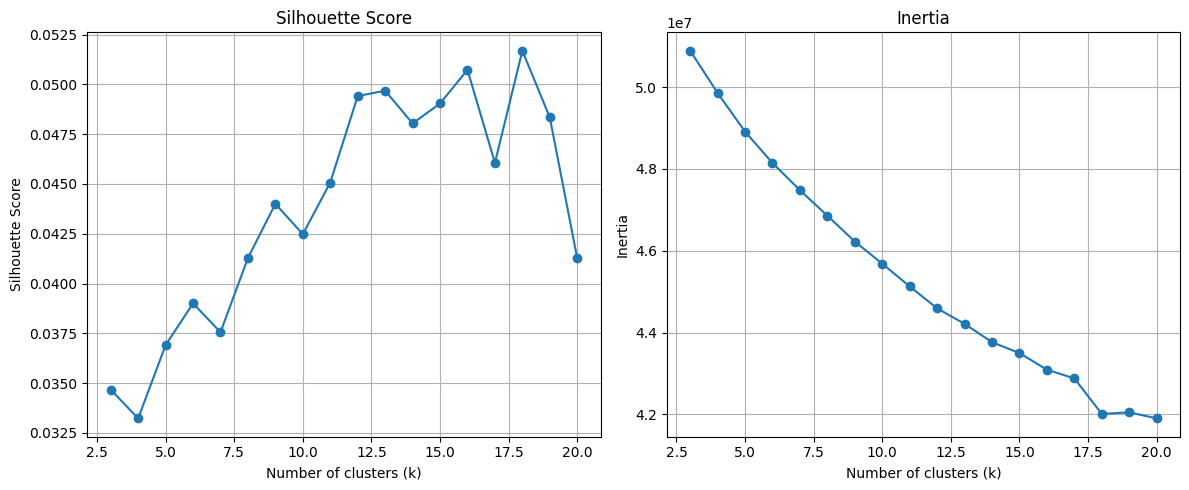

In [8]:
silhouettes = []
inertias = []
ks = [k for k in range(3, 21)]

#como calcular silhouette es muy pesado, predigo sobre un sample aleatorio con menos muestras
np.random.seed(42)
idx = np.random.choice(len(X_scaled), size=10000, replace=False)
X_sample = X_scaled[idx]

for k in ks:
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10) #n_init: cant de veces q se vuelve a correr el algoritmo con diferentes centroides, ayuda a obtener mejores resultados, deja de depender tanto del centroide inicial elegido
    kmeans.fit(X_scaled)

    #para inertia
    inertias.append(kmeans.inertia_)

    #para silhouette
    clusters = kmeans.predict(X_sample)
    silhouettes.append(silhouette_score(X_sample, clusters))

plot_silhouette_inercia(ks, silhouettes, inertias)

No hay un k optimo claro, elijo k = 16. 

In [9]:
k = 16
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)
df["cluster"] = clusters #guardo en el df el cluster al que pertenece cada libro

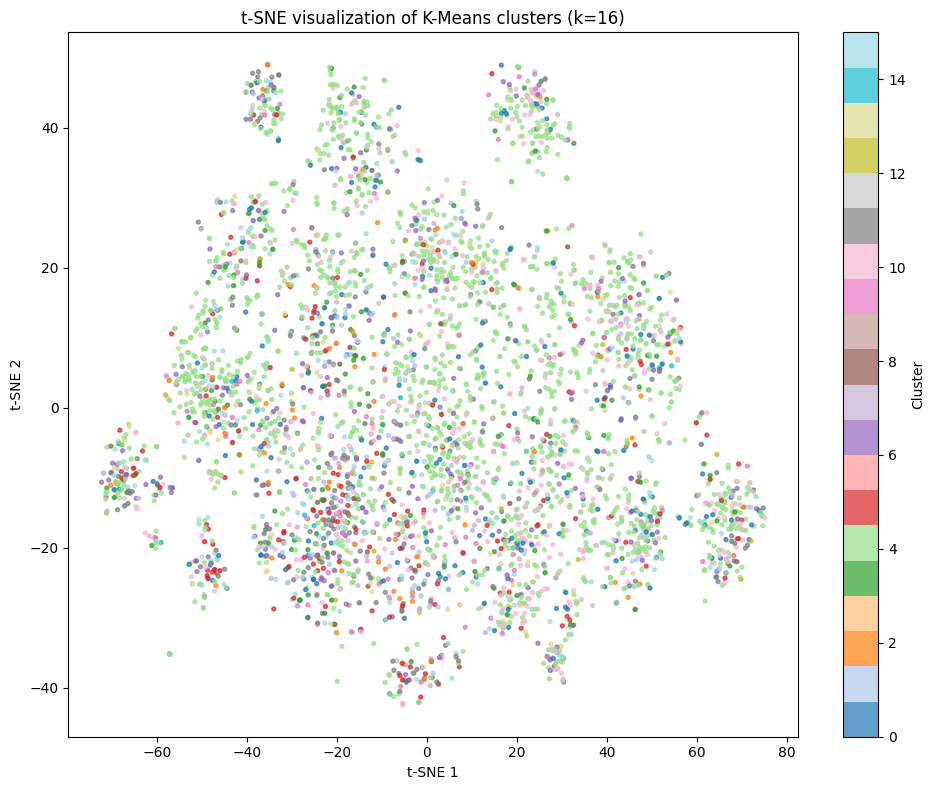

In [10]:
idx = np.random.choice(len(X_scaled), size=4000, replace=False)
X_sample = X_scaled[idx]
clusters_sample = clusters[idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca")
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters_sample, cmap="tab20", s=8, alpha=0.7)
plt.colorbar(scatter, label="Cluster")
plt.title(f"t-SNE visualization of K-Means clusters (k={k})")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

Como una segunda tecnica de recomendador, habiamos pensado en primer lugar hacer clustering, y luego elegir libros de ese grupo. Debido a la cantidad de muestras que tenemos, elegimos implementar KMeans. Sin embargo, debido a la cantidad de dimensiones que presenta nuestro dataset, no se lograron armar buenos clusters. Decidimos descartar este metodo de recomendacion y quedarnos con KNN. 

# Desarrollando recomendador

Una vez ya entrenado el modelo, vuelvo a unificar df_recomendador (con las features no numericas necesarias para identificar al libro) y df (con las features necesarias para entrenar)

In [11]:
df = pd.concat([df_recomendador, df], axis=1)

Defino dos funciones segun la informacion del libro que tenga: <br>
Si se tiene el indice del dataset en el que se encuentra el libro, usar recomendar_por_idx (usado en un ejemplo elegido a mano, o con un indice aleatorio). <br>
En cambio, si se tiene el titulo y autor escritos de manera exacta como en el dataset, usar recomendar_por_libro (usado en la interfaz grafica). <br>

### Libro elegido a mano para analizar el funcionamiento del recomendador

Ejemplo de recomendador para un libro especifico:

In [ ]:
#Para evitar tener que recorrer el dataset de libros cada vez que quiero buscar un libro, me creo un diccionario que asocia "titulo_autor" con su indice:
titulo_a_indice = dict(zip(df["titulo_autor"], df.index)) #Reduce el tiempo de busqueda, lo que nos sirve con el dataset grande

indice_consultado = df[df_recomendador["title"] == "The Book Thief"].index[0]
indices_recomendados, distancias = recomendar_por_idx(modelo, X_scaled, indice_consultado, titulo_a_indice, n_recomendaciones = 10)

print("\nRecomendaciones:")
for idx, dist in zip(indices_recomendados, distancias):
    print(f"{df_recomendador.iloc[idx]['title']}  (distancia = {dist:.4f})")


Recomendaciones:
The Book of Aron  (distancia = 0.2617)
The Wish Child  (distancia = 0.2738)
Saving Rafael  (distancia = 0.3073)
La luz que no puedes ver  (distancia = 0.3089)
Alone In Berlin  (distancia = 0.3419)
Every Man Dies Alone  (distancia = 0.3441)
A Book of Memories  (distancia = 0.3553)
The Other Half of Life: A Novel Based on the True Story of the MS St. Louis  (distancia = 0.3713)
The Cocaine Salesman  (distancia = 0.3720)
Little Man, What Now?  (distancia = 0.3725)


Verificamos visualmente las distancias en el dataset usando T-SNE. 

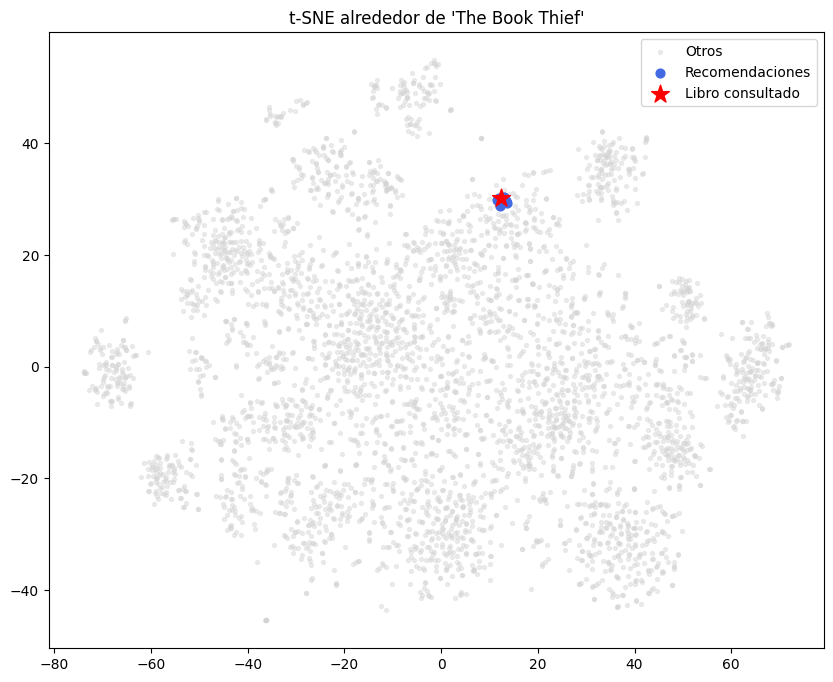

In [14]:
#hay tantos datos que no se puede visualizar correctamente en un grafico
#para tratar con esto, tomo 4000 muestras aleatorias, y para asegurarme que este mi libro y sus recomendaciones, los agrego a mano
muestra = np.random.choice(len(X_scaled), size=4000, replace=False)
muestra = np.unique(np.concatenate([muestra, indices_recomendados, [indice_consultado]]))

plot_vecinos_knn(muestra, X_scaled, indice_consultado, indices_recomendados, df_recomendador)

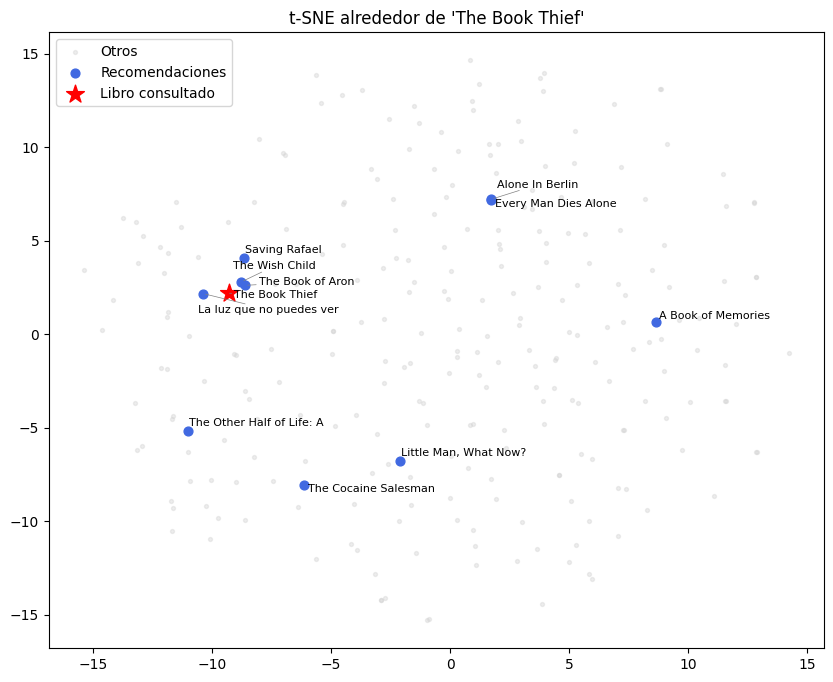

In [15]:
#mismo grafico pero con zoom y etiquetas en los nombres
#para este grafico no quiero 4000 muestras, sino solo el libro consultado, sus vecinos, y los vecinos de los vecinos
muestra = {indice_consultado}
muestra.update(indices_recomendados)

#agregar vecinos de las recomendaciones
for i in indices_recomendados:
    _, nuevos_indices = modelo.kneighbors(X_scaled[i].reshape(1, -1), n_neighbors=50)
    muestra.update(nuevos_indices[0])
muestra = np.array(sorted(muestra))

plot_vecinos_knn(muestra, X_scaled, indice_consultado, indices_recomendados, df_recomendador, etiquetas = True)

## Interfaz grafica

Para una mejor experiencia con el usuario, implementamos con la ayuda de ChatGPT una interfaz grafica con barra de busqueda.

In [19]:
all_titles = sorted(df["titulo_autor"].dropna().unique().tolist())

search_text = widgets.Text(
    placeholder="Escribí un libro...",
    description="Buscar:",
    layout=widgets.Layout(width="700px")
)

match_selector = widgets.Select(
    options=[],
    rows=10,
    layout=widgets.Layout(width="700px", height="220px")
)

def actualizar_opciones(change):
    texto = (change["new"] or "").strip().lower()

    if len(texto) < 2:
        match_selector.options = []
        return

    matches = [t for t in all_titles if texto in t.lower()][:50]
    match_selector.options = matches



search_text.observe(actualizar_opciones, names="value")

boton_recomendar = widgets.Button(
    description="Recomendar",
    button_style="success",
    icon="search",
    layout=widgets.Layout(width="220px", height="45px")
)

salida = widgets.HTML()

def al_hacer_click(boton):

    titulo_autor = match_selector.value

    recomendaciones = recomendar_por_libro(
        modelo,
        df,
        X_scaled,
        titulo_autor,
        titulo_a_indice
    )

    if recomendaciones is not None:
        salida.value = mostrar_recomendaciones(recomendaciones)
    else:
        salida.value = ""

boton_recomendar._click_handlers.callbacks.clear()
boton_recomendar.on_click(al_hacer_click)

titulo = widgets.HTML(
"""
<h1 style="color:#2E86C1;">
📚 Recomendador de Libros
</h1>

<p>
Escribí el nombre de un libro y elegilo de la lista.
</p>
"""
)

interfaz = widgets.VBox([
    titulo,
    search_text,
    match_selector,
    boton_recomendar,
    salida
])

display(interfaz)

Disclaimer: El aviso de la celda de arriba no es un error, simplemente tienen que volver a correr la celda para poder ver la interfaz (al hacer push a github, aparece el aviso). Pero, para eso tambien van a tener que volver a correr las celdas anteriores para cargar las variables que usa. Entonces, les recomendamos que si quieren verlo antes de la exposicion, no corran las celdas relacionadas con la busqueda del mejor K, porque tardan mucho. 